<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/Custom_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Custom datasets in pytorch


In [5]:
import torch
from torch import nn


torch.__version__

'2.14.1+cpu'

In [6]:
device = "cuda" if torch.cuda.is_available() else "gpu"
device


'gpu'

In [7]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


### Getting data from food101 we are using subsets of it

In [8]:
import requests
import zipfile
from pathlib import Path

## setingup path to a data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"
#if image folder does not exist create one
if image_path.is_dir():
  print(f"{image_path} directory already exist...skipping download")
else:
  print(f"{image_path} does not exist, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)
# download data (file)
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print(f"downloading data")
  f.write(request.content)
# unzip the data(file)
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
  print("unzipping file to get data")
  zip_ref.extractall(image_path)

data/pizza_steak_sushi directory already exist...skipping download
downloading data
unzipping file to get data


In [9]:
image_path

PosixPath('data/pizza_steak_sushi')

### Data preparation and data exploratation

In [10]:
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames,filenames in os.walk(dir_path):
    print(f"there are {len(dirnames)} directories and {len(filenames)} images in {dirpath}")

In [11]:
walk_through_dir(image_path)

there are 2 directories and 0 images in data/pizza_steak_sushi
there are 3 directories and 0 images in data/pizza_steak_sushi/test
there are 0 directories and 19 images in data/pizza_steak_sushi/test/steak
there are 0 directories and 25 images in data/pizza_steak_sushi/test/pizza
there are 0 directories and 31 images in data/pizza_steak_sushi/test/sushi
there are 3 directories and 0 images in data/pizza_steak_sushi/train
there are 0 directories and 75 images in data/pizza_steak_sushi/train/steak
there are 0 directories and 78 images in data/pizza_steak_sushi/train/pizza
there are 0 directories and 72 images in data/pizza_steak_sushi/train/sushi


In [12]:
# setup train and test path

train_dir = image_path / "train"
test_dir = image_path / "test"


train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

### Visualizing images

random image path:data/pizza_steak_sushi/train/sushi/2574453.jpg
image class:sushi
image height:512
image width:512


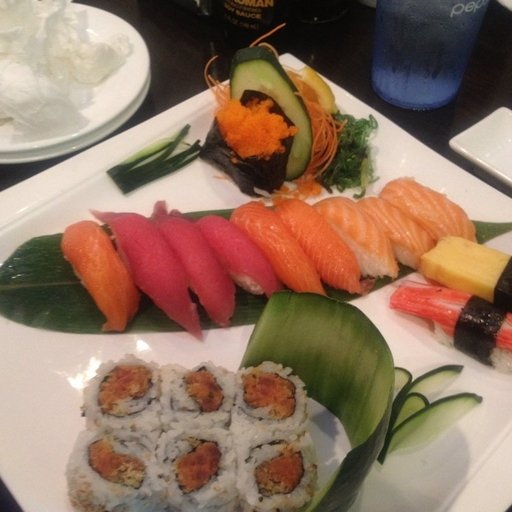

In [13]:

import matplotlib.pyplot as plt
import random
from  PIL import Image

# random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg")) # dir->file->content


random_image_path = random.choice(image_path_list)

random_image_path

image_class = random_image_path.parent.stem


img = Image.open(random_image_path)

print(f"random image path:{random_image_path}")
print(f"image class:{image_class}")
print(f"image height:{img.height}")
print(f"image width:{img.width}")
img


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

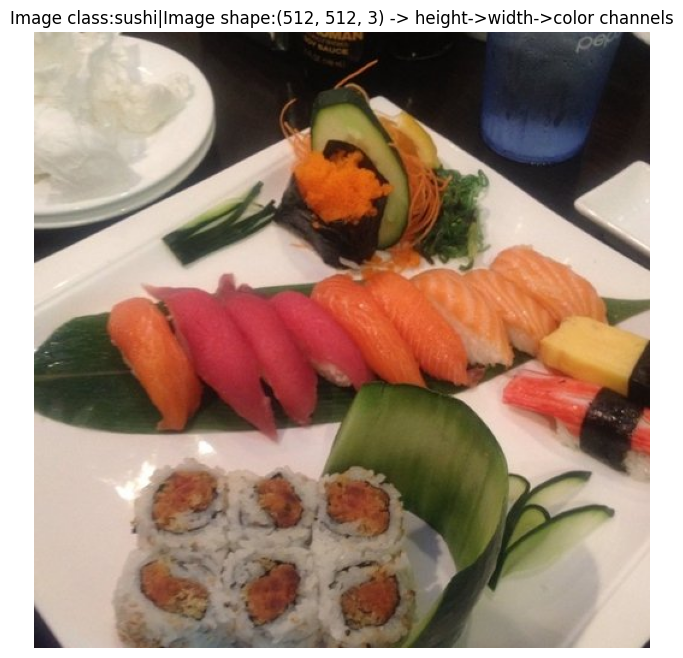

In [14]:
import numpy as np
import matplotlib.pyplot as plt


img_as_array = np.asarray(img)
plt.figure(figsize=(12,8))
plt.imshow(img_as_array)
plt.title(f"Image class:{image_class}|Image shape:{img_as_array.shape} -> height->width->color channels")
plt.axis(False)


### Transforming data into tensors
before using any kind of data turn it into tensors
`Datasets & DataLoaders`

In [15]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms



In [16]:
data_transform = transforms.Compose([
    #resize images
    transforms.Resize(size=(64,64)),
    #Flip the images
    transforms.RandomHorizontalFlip(p=0.5),
    #turning image into torch.tensor
    transforms.ToTensor()
])
data_transform(img).dtype

torch.float32

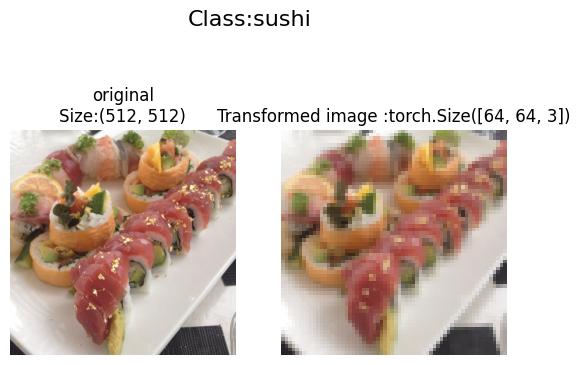

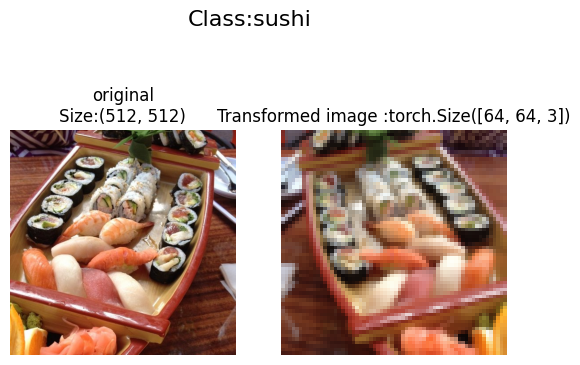

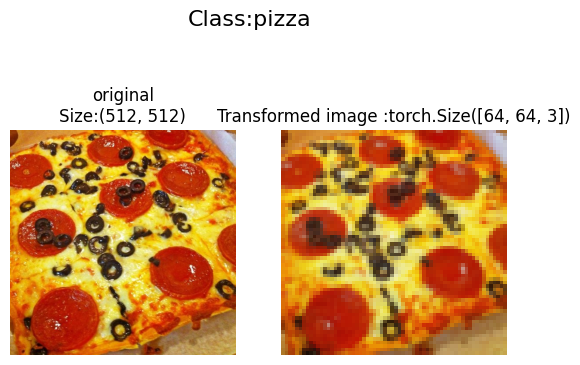

In [17]:
def plot_transformed_images(image_path,
                             transform,
                             n=3,
                             seed=42):
  if seed:
    random.seed(seed)
  random_image_path = random.sample(image_path, k=n)
  for image_path in random_image_path:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(nrows=1,ncols=2)
      ax[0].imshow(f)
      ax[0].set_title(f"original\nSize:{f.size}")
      ax[0].axis(False)

      transformed_image = transform(f).permute(1,2,0)#color, height,width
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed image :{transformed_image.shape}")
      ax[1].axis(False)

      fig.suptitle(f"Class:{image_path.parent.stem}", fontsize=16)


plot_transformed_images(image_path=image_path_list,
                        transform=data_transform,
                        n=3,
                        seed=None)


### Loading images data using ImageFolder

In [18]:
from torchvision import datasets

train_data = datasets.ImageFolder(root=train_dir,
                                  transform=data_transform,
                                  target_transform=None)
test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform,
                                 )

train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [19]:
class_name = test_data.classes
class_name

['pizza', 'steak', 'sushi']

In [20]:
inx_name = test_data.class_to_idx
inx_name

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [21]:
len(train_data), len(test_data)

(225, 75)

In [22]:
img, label = train_data[0][0],train_data[0][1]
img, label

(tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
          [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
          [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
          ...,
          [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
          [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
          [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],
 
         [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
          [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
          [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
          ...,
          [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
          [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
          [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],
 
         [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
          [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
          [0.0196, 0.0157, 0.0157,  ...,

In [23]:
class_name[label]

'pizza'

original shape:torch.Size([3, 64, 64])
after permute:torch.Size([64, 64, 3])


Text(0.5, 1.0, 'pizza')

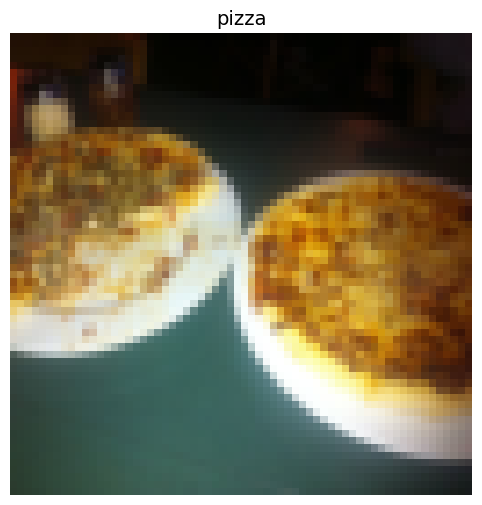

In [24]:
img_permute = img.permute(1,2,0)

print(f"original shape:{img.shape}")
print(f"after permute:{img_permute.shape}")

plt.figure(figsize=(10,6))
plt.imshow(img_permute)
plt.axis(False)
plt.title(class_name[label], fontsize=14)

In [25]:
import os
os.cpu_count()

2

### Turning datasets into dataloader

In [26]:
from torch.utils.data import DataLoader
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=1,
                              num_workers=1,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=1,
                             num_workers=1,
                             shuffle=False)

len(train_dataloader), len(test_dataloader)

(225, 75)

In [27]:
img, label = next(iter(train_dataloader))

print(f"image shape : {img.shape}")
print(f"label shape: {label.shape}")

image shape : torch.Size([1, 3, 64, 64])
label shape: torch.Size([1])


### loading iamge data with a custom datasets

In [29]:
import os
import pathlib
import torch


from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

## creating helper function to get class name

target_directory = train_dir
print(f"target dir {target_directory}")

class_name_found = sorted([entry.name for entry in list(os.scandir(target_directory))])

class_name_found

target dir data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [30]:
list(os.scandir(target_directory))

[<DirEntry 'steak'>, <DirEntry 'pizza'>, <DirEntry 'sushi'>]

In [31]:
def find_classes(directory:str)-> Tuple[list[str], Dict[str,int]]:
  classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

  if not classes:
    raise FileNotFoundError(f"couldn't find any classes in{directory}...please check file structure")
  class_to_idx = {class_name: i for i, class_name in enumerate(classes)}
  return classes, class_to_idx

In [32]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [40]:
import torch
from torch.utils.data import Dataset

class ImageFolderCustom(Dataset):
  def __init__(self, tar_dir:str,transform=None):
    self.paths = list(pathlib.Path(tar_dir).glob("*/*.jpg"))
    self.transform = transform
    self.classes, self.class_to_idx = find_classes(tar_dir)


  def  load_Image(self, index:int) -> Image.Image:
    image_path = self.paths[index]
    return Image.open(image_path)

  def __len__(self) -> int:
    return len(self.paths)


  def __getitem__(self, index:int) -> Tuple[torch.Tensor, int]:
    img = self.load_Image(index)
    class_name = self.paths[index].parent.name
    class_to_idx = self.class_to_idx[class_name]

    if self.transform:
      return self.transform(img), class_to_idx
    else:
      return img, class_to_idx

ImageFolderCustom(target_directory)

In [43]:
train_transforms = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.transforms.ToTensor()
])


In [45]:
train_data_custom = ImageFolderCustom(tar_dir=train_dir,
                                      transform=train_transforms)

test_data_custom = ImageFolderCustom(tar_dir=test_dir,
                                     transform=test_transform)

In [46]:
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7ab80f1e6350>,
 <__main__.ImageFolderCustom at 0x7ab80f2b1cd0>)

In [54]:
print(len(train_data), len(train_data_custom))
print(len(test_data), len(test_data_custom))
print(train_data_custom.classes == train_data.classes)
print(test_data_custom.classes == test_data.classes)

225 225
75 75
True
True


### Creating custom imagefolder class

In [81]:
def DisplayRandomImages(dataset: torch.utils.data.Dataset,
                        classes:List[str] = True,
                        n:int = 10,
                        display_shape:bool = True,
                        seed: int=None):
  if n > 10:
    n=10
    display_shape = False
    print(f"For display purpose n shouldn't be larger then 10")

  if seed:
    random.seed(seed)


  plt.figure(figsize=(16,8))

  random_samples_idx = random.sample(range(len(dataset)), k=n)

  for i, tar_sample in enumerate(random_samples_idx):
    tar_image, tar_label = dataset[tar_sample][0], dataset[tar_sample][1]

    tar_image_adjust = tar_image.permute(1,2,0)

    plt.subplot(1, n, i+1)
    plt.imshow(tar_image_adjust)
    plt.axis(False)
    if classes:
      title = f"classes:{classes[tar_label]}"
      if display_shape:
        title = title + f"\nshape:{tar_image_adjust.shape}"
      plt.title(title)




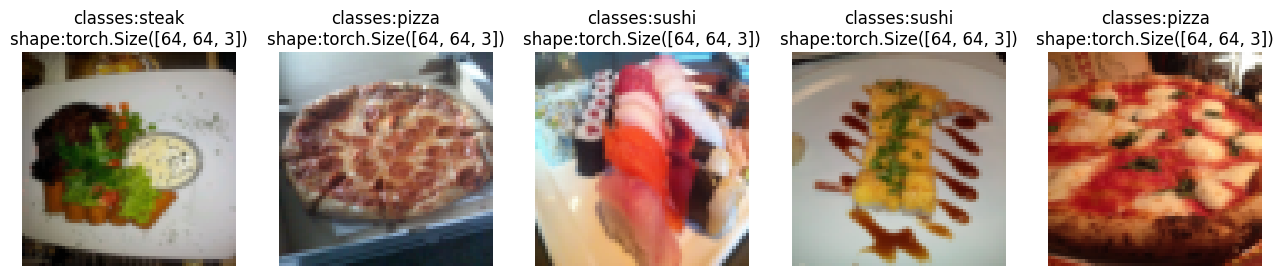

In [82]:
DisplayRandomImages(train_data,
                    n=5,
                    classes=class_name,
                    seed=None)

For display purpose n shouldn't be larger then 10


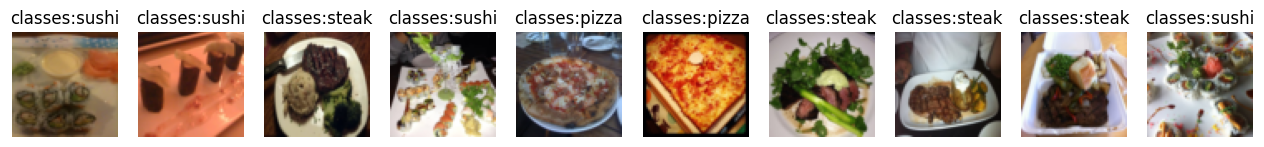

In [83]:
DisplayRandomImages(train_data_custom,
                    n=11,
                    classes=class_name,
                    seed=None)

### Using custom datasets creating dataloaders

In [90]:
from torch.utils.data import DataLoader
train_custom_dataloader = DataLoader(dataset=train_data_custom,
                              batch_size=1,
                              num_workers=0,
                              shuffle=True)
test_custom_dataloader = DataLoader(dataset=test_data_custom,
                             batch_size=1,
                             num_workers=0,
                             shuffle=False)

print(len(train_custom_dataloader), len(test_custom_dataloader))
print(len(train_dataloader), len(test_dataloader))

225 75
225 75


In [94]:
img_custom, label_custom = next(iter(train_custom_dataloader))
img_custom.shape, label_custom.shape

(torch.Size([1, 3, 64, 64]), torch.Size([1]))